# FIFA World Cup 2026 – Objective 2

This notebook brings together the variables our group tested. Mel prepared the 2.1 variables, Manish prepared four of the 2.2 variables, and I worked on my own variables and the regression models. I tested goal difference using 104 matches and team goals using 208 team-match rows. Both models use eight predictors.

## 1. Load the data

For 2.1, I used Mel's updated CSV. For 2.2, I used the combined 208-row dataset in `Outputs`. I checked the number of rows, selected the eight predictors for each model and looked for missing values.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split, GroupKFold
from sklearn.impute import SimpleImputer
from sklearn.pipeline import make_pipeline
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from IPython.display import display

HERE = Path.cwd()
output_dir = HERE / 'Outputs'
output_dir.mkdir(exist_ok=True)

df21 = pd.read_csv(HERE / 'FIFA2026_Objective2_1_Goal_Difference_104_Matches.csv')
df22 = pd.read_csv(output_dir / 'Objective2_2_Integrated_208.csv')

x21 = ['X1_Past7_WinRate_Diff', 'X2_Past7_GoalsConceded_Diff',
       'X3_WC_Participations_Diff', 'X4_MostExpPlayer_Pre2026_Diff',
       'X5_Prior_WC_GoalDifference_Diff', 'X6_Prior_WC_WinRate_Diff',
       'X7_Pre-Match_Unbeaten_Rate', 'X8_PreMatch_Computed_Elo_Diff']
x22 = ['PreMatch_Elo_Difference', 'Pre2026_WC_Participation_Difference',
       'Opponent_Loss_Rate_Last7', 'PreMatch_Unbeaten_Rate_Last7',
       'X5_Prior_WC_Team_AvgGoals', 'X6_Prior_WC_Opp_AvgConceded',
       'X7_Avg_SquadAge_Team', 'X8_DaysSincePrevInternational_Team']
y21, y22 = 'Y_GoalDifference', 'Y_TeamGoals'

for df, cols, target, expected in [(df21,x21,y21,104),(df22,x22,y22,208)]:
    assert len(df) == expected and df['Match_ID'].nunique() == 104
    assert len(cols) == 8 and set(cols + [target]).issubset(df.columns)
    df['Date'] = pd.to_datetime(df['Date'])
    for c in cols + [target]:
        df[c] = pd.to_numeric(df[c], errors='coerce')
    assert df[target].notna().all()

print('Objective 2.1:', df21.shape, '— 8 predictors')
print('Objective 2.2:', df22.shape, '— 8 predictors')
print('Missing values, 2.1:')
print(df21[x21].isna().sum())
print('Missing values, 2.2:')
print(df22[x22].isna().sum())

Objective 2.1: (104, 17) — 8 predictors
Objective 2.2: (208, 14) — 8 predictors
Missing values, 2.1:
X1_Past7_WinRate_Diff               0
X2_Past7_GoalsConceded_Diff         0
X3_WC_Participations_Diff           0
X4_MostExpPlayer_Pre2026_Diff       0
X5_Prior_WC_GoalDifference_Diff    24
X6_Prior_WC_WinRate_Diff           24
X7_Pre-Match_Unbeaten_Rate          0
X8_PreMatch_Computed_Elo_Diff       0
dtype: int64
Missing values, 2.2:
PreMatch_Elo_Difference                 0
Pre2026_WC_Participation_Difference     0
Opponent_Loss_Rate_Last7                0
PreMatch_Unbeaten_Rate_Last7            0
X5_Prior_WC_Team_AvgGoals              48
X6_Prior_WC_Opp_AvgConceded            48
X7_Avg_SquadAge_Team                    0
X8_DaysSincePrevInternational_Team      0
dtype: int64


## 2. Scatterplots and correlations

I made scatterplots to see whether each variable has a roughly linear relationship with the result. Some early matches have no previous World Cup data, so those points are left out of the individual scatterplots.

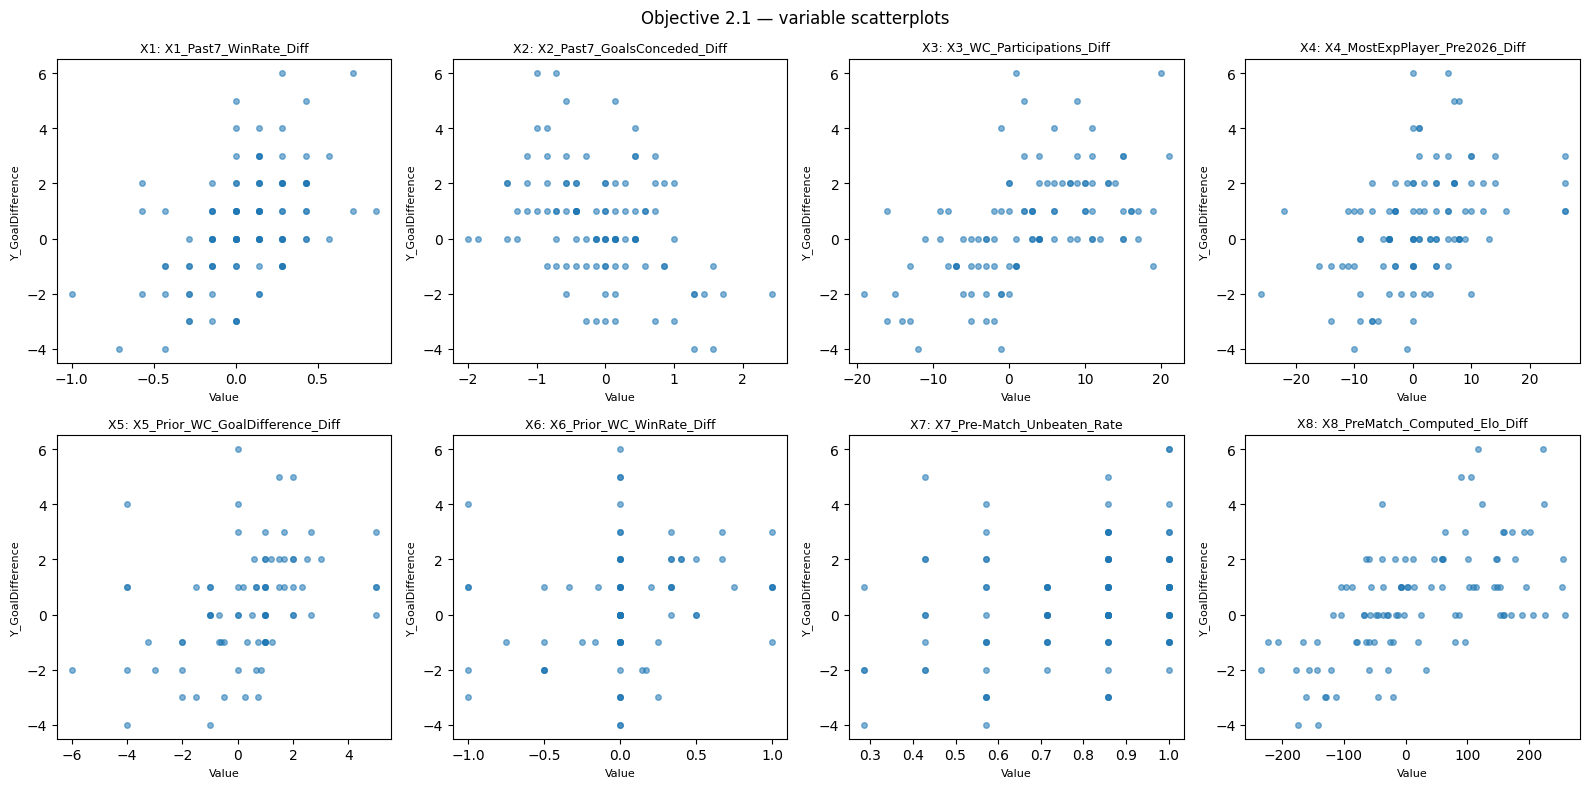

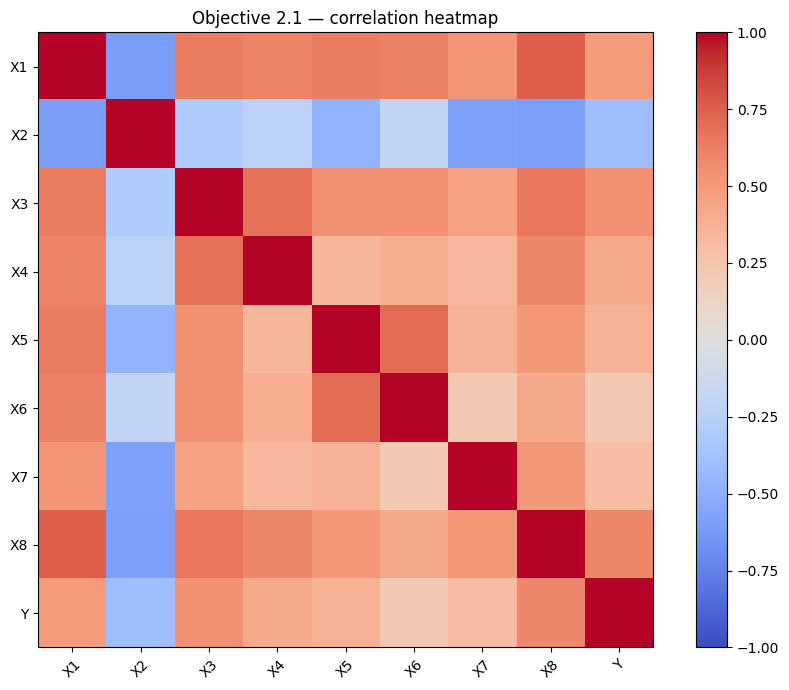

,Correlation with target
X1_Past7_WinRate_Diff,0.489
X2_Past7_GoalsConceded_Diff,-0.393
X3_WC_Participations_Diff,0.546
X4_MostExpPlayer_Pre2026_Diff,0.406
X5_Prior_WC_GoalDifference_Diff,0.371
X6_Prior_WC_WinRate_Diff,0.212
X7_Pre-Match_Unbeaten_Rate,0.292
X8_PreMatch_Computed_Elo_Diff,0.589


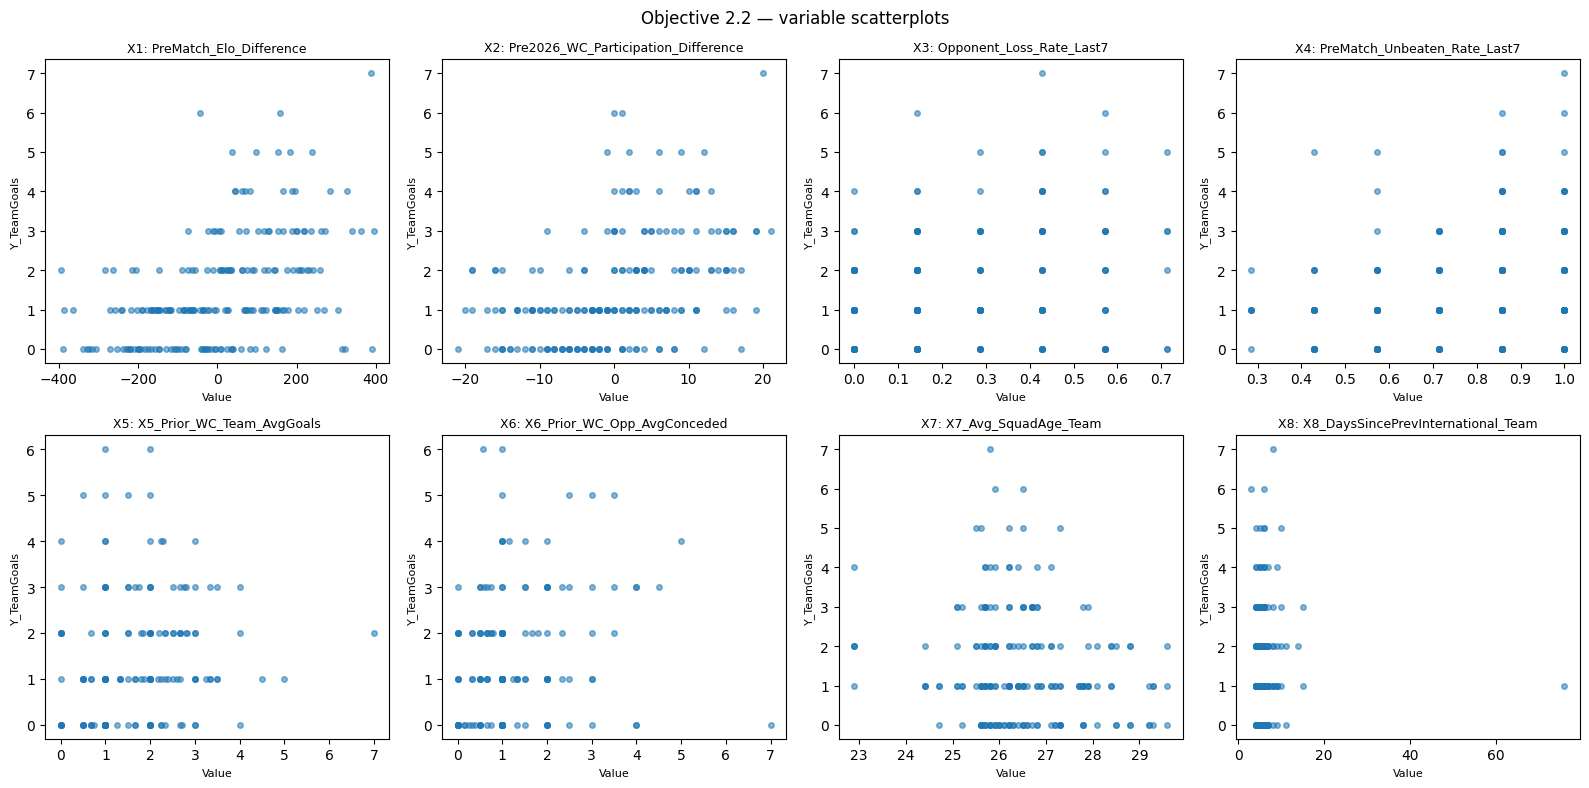

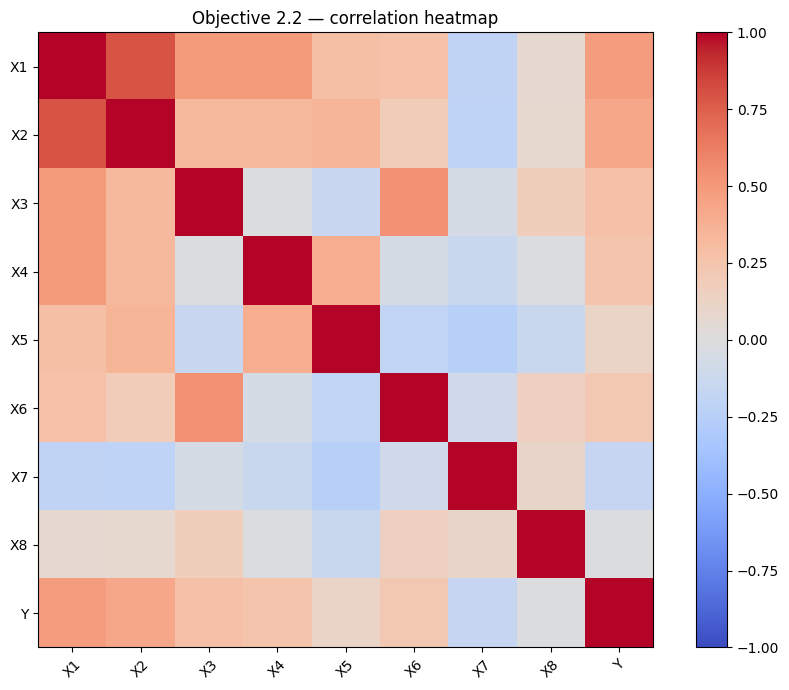

,Correlation with target
PreMatch_Elo_Difference,0.477
Pre2026_WC_Participation_Difference,0.428
Opponent_Loss_Rate_Last7,0.278
PreMatch_Unbeaten_Rate_Last7,0.247
X5_Prior_WC_Team_AvgGoals,0.111
X6_Prior_WC_Opp_AvgConceded,0.215
X7_Avg_SquadAge_Team,-0.171
X8_DaysSincePrevInternational_Team,-0.013


In [2]:
def plots_and_correlations(data, features, target, label):
    fig, axes = plt.subplots(2, 4, figsize=(16, 8))
    for i, col in enumerate(features):
        xy = data[[col, target]].dropna()
        ax = axes.flat[i]
        ax.scatter(xy[col], xy[target], s=16, alpha=0.55)
        ax.set_title(f'X{i+1}: {col}', fontsize=9)
        ax.set_xlabel('Value', fontsize=8)
        ax.set_ylabel(target, fontsize=8)
    fig.suptitle(f'Objective {label} — variable scatterplots')
    fig.tight_layout()
    fig.savefig(output_dir / f'Objective{label.replace(".", "_")}_Variable_Scatterplots.png', dpi=170)
    plt.show()

    corr = data[features + [target]].corr()
    fig, ax = plt.subplots(figsize=(9, 7))
    im = ax.imshow(corr, vmin=-1, vmax=1, cmap='coolwarm')
    ax.set_xticks(range(9), [f'X{i+1}' for i in range(8)] + ['Y'], rotation=45)
    ax.set_yticks(range(9), [f'X{i+1}' for i in range(8)] + ['Y'])
    fig.colorbar(im, ax=ax)
    ax.set_title(f'Objective {label} — correlation heatmap')
    fig.tight_layout()
    fig.savefig(output_dir / f'Objective{label.replace(".", "_")}_Correlation_Heatmap.png', dpi=170)
    plt.show()
    display(corr[target].drop(target).round(3).to_frame('Correlation with target'))

plots_and_correlations(df21, x21, y21, '2.1')
plots_and_correlations(df22, x22, y22, '2.2')

## 3. Train/test splits

I compared 60/40, 70/30 and 80/20 random splits, then tested an 80/20 split based on match date. For 2.2, I kept the two teams from the same match together. I only used the training data to fill missing predictor values.

In [3]:
def fit_test(df, features, target, test_size=0.2, chronological=False):
    matches = df[['Match_ID','Date']].drop_duplicates('Match_ID').sort_values(['Date','Match_ID'])
    if chronological:
        point = int(len(matches) * (1-test_size))
        train_ids = set(matches.iloc[:point]['Match_ID'])
        test_ids = set(matches.iloc[point:]['Match_ID'])
    else:
        a, b = train_test_split(matches['Match_ID'].to_numpy(), test_size=test_size, random_state=42)
        train_ids, test_ids = set(a), set(b)
    assert not train_ids.intersection(test_ids)
    train = df[df.Match_ID.isin(train_ids)].copy()
    test = df[df.Match_ID.isin(test_ids)].copy()
    fill = train[features].median().fillna(0)
    model = LinearRegression()
    model.fit(train[features].fillna(fill), train[target])
    actual = test[target].to_numpy()
    pred = model.predict(test[features].fillna(fill))
    return {'Train rows':len(train),'Test rows':len(test),
            'MAE':mean_absolute_error(actual,pred),
            'RMSE':np.sqrt(mean_squared_error(actual,pred)),
            'R2':r2_score(actual,pred)}, model, actual, pred, train, test

results = []
final_models = {}
for label, data, cols, target in [('2.1',df21,x21,y21),('2.2',df22,x22,y22)]:
    for test_size in [0.4, 0.3, 0.2]:
        result, *_ = fit_test(data, cols, target, test_size)
        results.append({'Objective':label,'Split':f'{int((1-test_size)*100)}/{int(test_size*100)}',**result})
    result, model, actual, pred, train, test = fit_test(data,cols,target,0.2,chronological=True)
    results.append({'Objective':label,'Split':'Chronological 80/20',**result})
    final_models[label]=(model,actual,pred,train,test,cols,target)

scores=pd.DataFrame(results)
display(scores.round(3))
scores.to_csv(output_dir / 'Train_Test_Split_Results.csv', index=False)

,Objective,Split,Train rows,Test rows,MAE,RMSE,R2
0,2.1,60/40,62,42,1.405,1.807,0.314
1,2.1,70/30,72,32,1.426,1.825,0.325
2,2.1,80/20,83,21,1.433,1.858,0.374
3,2.1,Chronological 80/20,83,21,1.191,1.503,0.037
4,2.2,60/40,124,84,0.915,1.189,0.242
5,2.2,70/30,144,64,0.925,1.215,0.273
6,2.2,80/20,166,42,0.919,1.204,0.324
7,2.2,Chronological 80/20,166,42,0.967,1.290,0.035


## 4. Five-fold cross-validation

I used GroupKFold to test the models on five different groups of matches from the training set. This avoids putting the two sides of a 2.2 match in different folds.

In [4]:
cv_rows=[]
for label in ['2.1','2.2']:
    model, actual, pred, train, test, cols, target = final_models[label]
    splitter=GroupKFold(n_splits=5)
    X=train[cols]
    y=train[target]
    for fold, (a,b) in enumerate(splitter.split(X,y,groups=train['Match_ID']),start=1):
        reg=make_pipeline(SimpleImputer(strategy='median'),LinearRegression())
        reg.fit(X.iloc[a],y.iloc[a])
        forecast=reg.predict(X.iloc[b])
        cv_rows.append({'Objective':label,'Fold':fold,
                        'Training matches':train.iloc[a].Match_ID.nunique(),
                        'Validation matches':train.iloc[b].Match_ID.nunique(),
                        'MAE':mean_absolute_error(y.iloc[b],forecast),
                        'RMSE':np.sqrt(mean_squared_error(y.iloc[b],forecast)),
                        'R2':r2_score(y.iloc[b],forecast)})
cv=pd.DataFrame(cv_rows)
display(cv.round(3))
display(cv.groupby('Objective')[['MAE','RMSE','R2']].mean().round(3))
cv.to_csv(output_dir / 'GroupKFold_5Fold_Results.csv', index=False)

,Objective,Fold,Training matches,Validation matches,MAE,RMSE,R2
0,2.1,1,66,17,1.214,1.472,0.293
1,2.1,2,66,17,1.541,2.105,-0.005
2,2.1,3,66,17,1.517,1.822,0.217
3,2.1,4,67,16,1.190,1.484,0.150
4,2.1,5,67,16,1.290,1.557,0.430
5,2.2,1,66,17,0.982,1.193,0.047
6,2.2,2,66,17,1.028,1.419,0.248
7,2.2,3,66,17,0.904,1.148,0.259
8,2.2,4,67,16,0.994,1.271,-0.285
9,2.2,5,67,16,0.881,1.241,0.291


,MAE,RMSE,R2
Objective,,,
2.1,1.350,1.688,0.217
2.2,0.958,1.254,0.112


## 5. Predictions and residuals

I plotted the predicted results against the actual results. I also checked the residuals to see where the predictions were too high or too low.

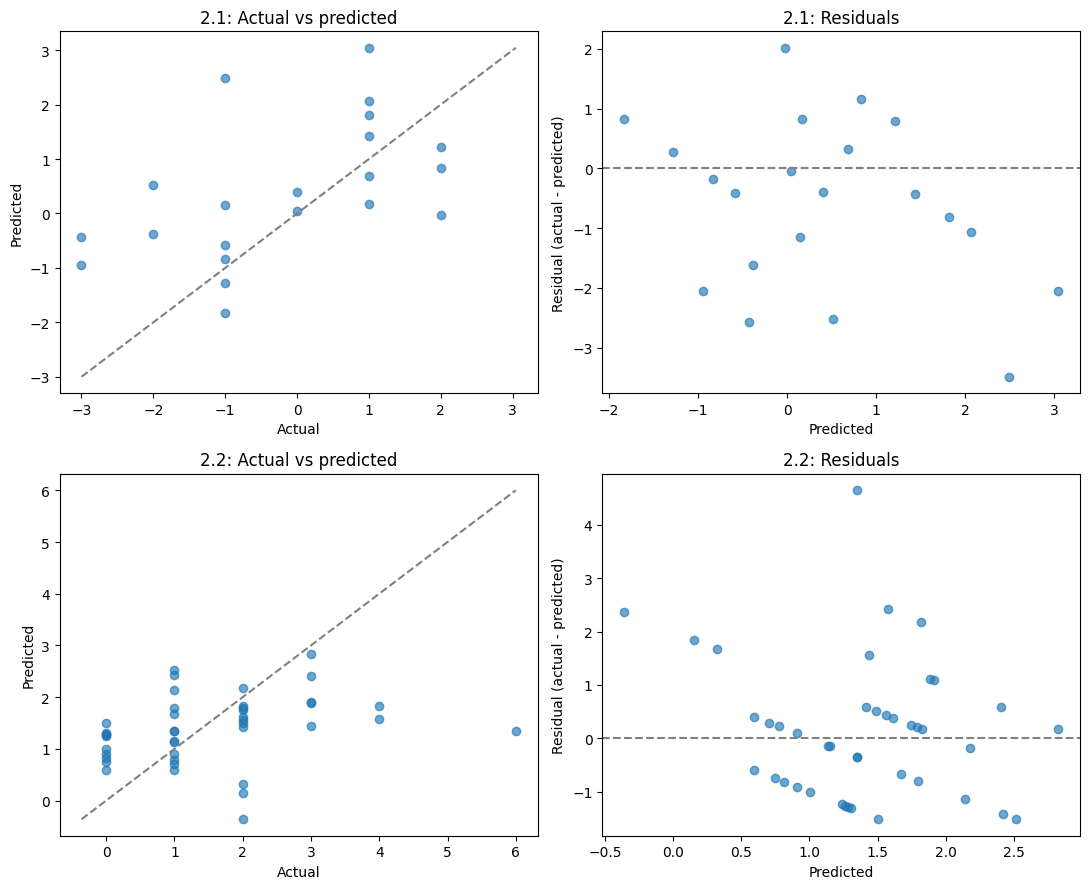

In [5]:
fig, axes = plt.subplots(2,2,figsize=(11,9))
for i,label in enumerate(['2.1','2.2']):
    model,actual,pred,train,test,cols,target=final_models[label]
    ax=axes[i,0]
    ax.scatter(actual,pred,alpha=0.65)
    low=min(actual.min(),pred.min());high=max(actual.max(),pred.max())
    ax.plot([low,high],[low,high],'--',color='grey')
    ax.set(xlabel='Actual',ylabel='Predicted',title=f'{label}: Actual vs predicted')
    ax=axes[i,1]
    ax.scatter(pred,actual-pred,alpha=0.65)
    ax.axhline(0,color='grey',linestyle='--')
    ax.set(xlabel='Predicted',ylabel='Residual (actual - predicted)',title=f'{label}: Residuals')
fig.tight_layout()
fig.savefig(output_dir / 'Objective2_Final_Predictions_and_Residuals.png',dpi=180)
plt.show()

## 6. Things to check before the report

The original CSVs were not changed by this notebook. The 2.1 model now reads Mel's updated CSV, while the 2.2 model still reads the combined file in `Outputs`. The 2.2 values should be checked against Manish's final GitHub CSV before we use the results in the report.

We also need to confirm that the age and World Cup participation figures were available before the relevant matches. Recent-match statistics can include earlier games in the 2026 tournament, but they must never include the match being predicted or any later match.